# Devoir 2 — Convergence Uniforme et Limites de l'Apprentissage

**Cours :** Apprentissage Statistique et Automatique — M2 IMDS  
**Étudiant :** *Kossi NOUMAGNO (M2 IMDS)*

## Objectif

Dans ce notebook, j'utilise des simulations pour comprendre trois concepts clés du cours :

1. **La convergence uniforme :** comment le risque empirique approche le risque réel, et pourquoi le contrôle simultané de toutes les hypothèses est plus difficile que le contrôle d'une seule hypothèse fixée.
2. **Le théorème du No-Free-Lunch:** pourquoi un algorithme d'apprentissage ne peut pas deviner de manière fiable des étiquettes arbitraires qu'il n'a jamais observées.
3. **Le biais inductif :** pourquoi restreindre la classe d'hypothèses peut rendre la généralisation possible lorsque cette restriction correspond à la structure de la cible.

Je comparerai les résultats des simulations avec les expressions théoriques du devoir et des sessions de cours. Les simulations ne sont pas des preuves : elles permettent d'illustrer la théorie pour les paramètres particuliers choisis ici.

## 0. Importations et paramètres de simulation

J'utilise uniquement NumPy pour les simulations et Matplotlib pour les figures, comme suggéré dans le devoir. Une graine aléatoire fixe (random seed) rend les expériences reproductibles lorsque les cellules sont exécutées dans l'ordre.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Fix the seed so that the results can be reproduced.
rng = np.random.default_rng(42)

# A common number of repetitions for the Monte-Carlo experiments.
N_REPETITIONS = 5_000

print("NumPy version:", np.__version__)
print("Number of Monte-Carlo repetitions:", N_REPETITIONS)

NumPy version: 2.1.3
Number of Monte-Carlo repetitions: 5000


## Partie I — Simulation de la Convergence Uniforme

### Rappel du cours

Pour une hypothèse fixée $h$, le risque empirique est la perte moyenne sur l'échantillon d'apprentissage :

$$
L_S(h)=\frac{1}{m}\sum_{i=1}^{m}\ell(h,z_i),
$$

tandis que le risque réel est l'espérance de la perte sous la distribution des données :

$$
L_D(h)=\mathbb{E}_{z\sim D}[\ell(h,z)].
$$

Pour la classification binaire avec la perte $0$-$1$, la perte est comprise dans $[0,1]$. Dans le modèle simplifié utilisé dans ce devoir, le nombre d'erreurs pour une hypothèse de risque réel $p$ suit une loi binomiale :

$$
E\sim\operatorname{Binomial}(m,p), \qquad L_S=\frac{E}{m}.
$$

Par conséquent,

$$
\mathbb{E}[L_S]=p, \qquad
\operatorname{Var}(L_S)=\frac{p(1-p)}{m}.
$$

Ainsi, le risque empirique est sans biais dans ce modèle, et sa variance diminue à mesure que la taille de l'échantillon augmente.

### Question 1 — Le risque empirique comme variable aléatoire

Je fixe une hypothèse avec un risque réel $p=0.35$, et je simule son risque empirique pour plusieurs tailles d'échantillon. Les histogrammes devraient se rétrécir à mesure que $m$ augmente. La moyenne empirique devrait rester proche de $p$, tandis que l'écart-type théorique diminue en $1/\sqrt{m}$.

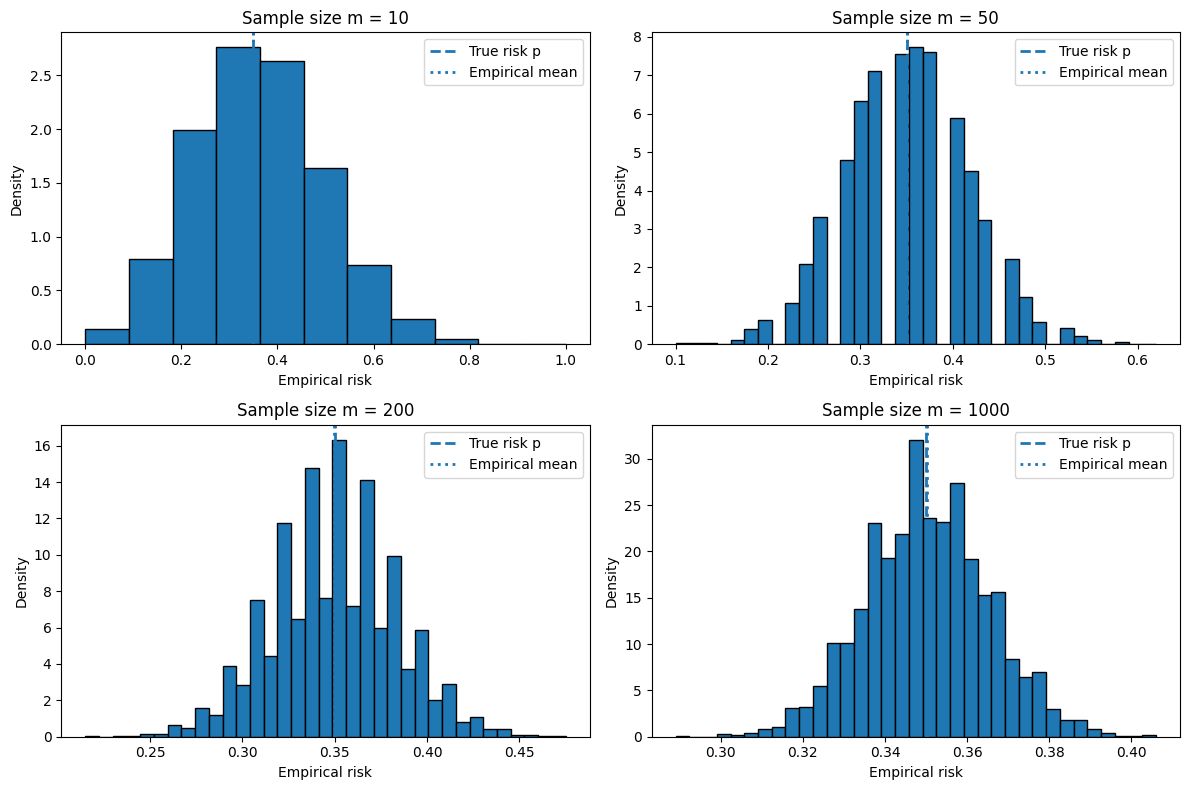

m | empirical mean | empirical std | theoretical std
  10 | 0.3489         | 0.1508        | 0.1508
  50 | 0.3506         | 0.0678        | 0.0675
 200 | 0.3496         | 0.0338        | 0.0337
1000 | 0.3502         | 0.0151        | 0.0151


In [2]:
p_true_q1 = 0.35
sample_sizes_q1 = [10, 50, 200, 1000]
n_sim_q1 = 10_000

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
summary_q1 = []

for ax, m in zip(axes.ravel(), sample_sizes_q1):
    # Simulate the number of errors and divide by m to obtain empirical risks.
    errors = rng.binomial(n=m, p=p_true_q1, size=n_sim_q1)
    empirical_risks = errors / m

    mean_emp = empirical_risks.mean()
    std_emp = empirical_risks.std(ddof=0)
    std_theory = np.sqrt(p_true_q1 * (1 - p_true_q1) / m)

    summary_q1.append((m, mean_emp, std_emp, std_theory))

    ax.hist(empirical_risks, bins=min(m + 1, 35), density=True, edgecolor="black")
    ax.axvline(p_true_q1, linestyle="--", linewidth=2, label="True risk p")
    ax.axvline(mean_emp, linestyle=":", linewidth=2, label="Empirical mean")
    ax.set_title(f"Sample size m = {m}")
    ax.set_xlabel("Empirical risk")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

print("m | empirical mean | empirical std | theoretical std")
for row in summary_q1:
    print(f"{row[0]:4d} | {row[1]:.4f}         | {row[2]:.4f}        | {row[3]:.4f}")

**Interprétation.** Le risque empirique moyen doit être proche du risque réel $p=0.35$, aux fluctuations de Monte-Carlo près. La dispersion devient plus faible pour les grandes valeurs de $m$, ce qui est en accord avec la formule de la variance $p(1-p)/m$. Il s'agit d'une première illustration de la concentration, mais elle ne concerne qu'une seule hypothèse fixée.

### Question 2 — Écart entre risque empirique et risque réel

Pour une hypothèse fixée, l'inégalité de Hoeffding donne :

$$
\Pr\left(|L_S(h)-L_D(h)|>\varepsilon\right)
\leq 2\exp(-2m\varepsilon^2).
$$

J'estime la probabilité de gauche par simulation et je la compare à la borne supérieure théorique. Comme l'expression de droite est une borne supérieure, elle n'a pas besoin de correspondre exactement à la probabilité empirique.

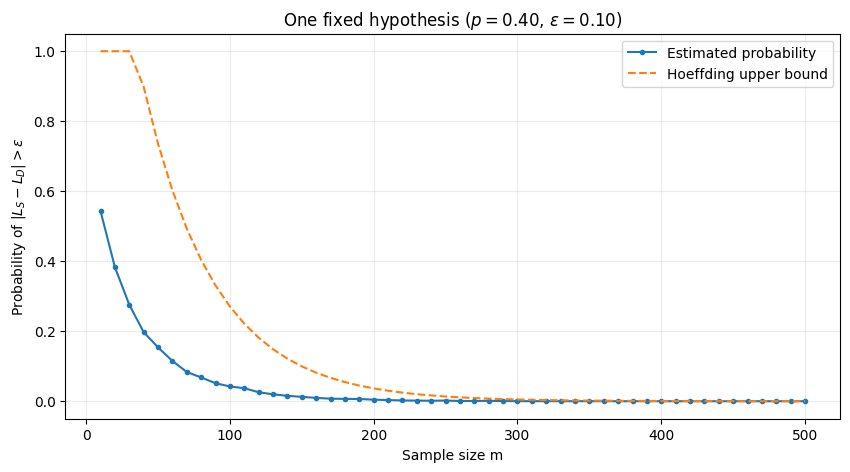

At the largest m:
Estimated probability = 0.0
Hoeffding bound       = 9e-05


In [3]:
p_true_q2 = 0.40
epsilon_q2 = 0.10
sample_sizes_q2 = np.arange(10, 501, 10)
n_sim_q2 = 10_000

empirical_prob_q2 = []
hoeffding_bound_q2 = []

for m in sample_sizes_q2:
    errors = rng.binomial(n=m, p=p_true_q2, size=n_sim_q2)
    empirical_risks = errors / m
    deviations = np.abs(empirical_risks - p_true_q2)

    empirical_prob_q2.append(np.mean(deviations > epsilon_q2))

    # A probability cannot exceed 1, so I cap the displayed bound at 1.
    bound = 2 * np.exp(-2 * m * epsilon_q2**2)
    hoeffding_bound_q2.append(min(1.0, bound))

plt.figure(figsize=(10, 5))
plt.plot(sample_sizes_q2, empirical_prob_q2, marker="o", markersize=3,
         label="Estimated probability")
plt.plot(sample_sizes_q2, hoeffding_bound_q2, linestyle="--",
         label="Hoeffding upper bound")
plt.xlabel("Sample size m")
plt.ylabel(r"Probability of $|L_S-L_D|>\varepsilon$")
plt.title(r"One fixed hypothesis ($p=0.40$, $\varepsilon=0.10$)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("At the largest m:")
print("Estimated probability =", round(empirical_prob_q2[-1], 5))
print("Hoeffding bound       =", round(hoeffding_bound_q2[-1], 5))

**Interprétation.** La probabilité estimée diminue globalement à mesure que la taille de l'échantillon augmente. La borne de Hoeffding diminue également, de manière exponentielle en $m\varepsilon^2$, mais elle peut être bien plus grande que la probabilité observée. Ce n'est pas une contradiction : Hoeffding fournit une borne supérieure suffisante, et non une formule exacte. Si aucun dépassement n'est observé sur un nombre fini de répétitions, la probabilité estimée est de zéro, mais la probabilité réelle n'est pas nécessairement nulle.

### Question 3 — De l'hypothèse unique à la convergence uniforme

Le cours insiste sur le fait que l'ERM (Minimisation du Risque Empirique) choisit son hypothèse en utilisant l'échantillon d'apprentissage. Par conséquent, une garantie pour une seule hypothèse fixée à l'avance ne suffit pas. Nous voulons que les risques empiriques et réels soient proches **simultanément pour toutes les hypothèses** de la classe.

Pour une classe finie $\mathcal{H}$, définissons :

$$
\Delta_S=\max_{h\in\mathcal{H}}|L_S(h)-L_D(h)|.
$$

En utilisant l'inégalité de Hoeffding pour chaque hypothèse et l'union bound (borne de l'union) :

$$
\Pr(\Delta_S>\varepsilon)
\leq 2|\mathcal{H}|\exp(-2m\varepsilon^2).
$$

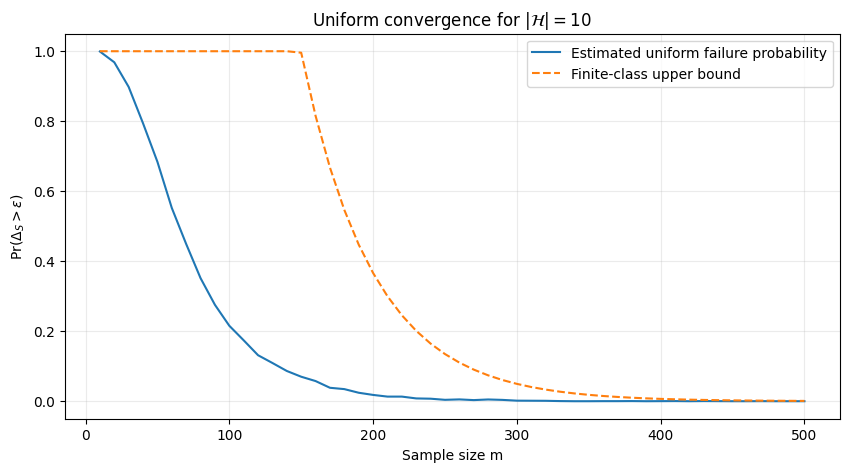

In [4]:
K_q3 = 10
epsilon_q3 = 0.10
sample_sizes_q3 = np.arange(10, 501, 10)
n_sim_q3 = 5_000

# Each hypothesis has a fixed true risk. These risks are held fixed as m changes.
true_risks_q3 = rng.uniform(0.1, 0.9, size=K_q3)

empirical_prob_q3 = []
uniform_bound_q3 = []

for m in sample_sizes_q3:
    # Each column represents one hypothesis; each row is one simulated experiment.
    errors = rng.binomial(
        n=m,
        p=true_risks_q3,
        size=(n_sim_q3, K_q3)
    )
    empirical_risks = errors / m
    max_deviation = np.max(np.abs(empirical_risks - true_risks_q3), axis=1)

    empirical_prob_q3.append(np.mean(max_deviation > epsilon_q3))
    bound = 2 * K_q3 * np.exp(-2 * m * epsilon_q3**2)
    uniform_bound_q3.append(min(1.0, bound))

plt.figure(figsize=(10, 5))
plt.plot(sample_sizes_q3, empirical_prob_q3, label="Estimated uniform failure probability")
plt.plot(sample_sizes_q3, uniform_bound_q3, linestyle="--",
         label="Finite-class upper bound")
plt.xlabel("Sample size m")
plt.ylabel(r"$\Pr(\Delta_S>\varepsilon)$")
plt.title(r"Uniform convergence for $|\mathcal{H}|=10$")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Interprétation.** La convergence uniforme échoue si au moins une hypothèse présente un écart supérieur à $\varepsilon$. Par conséquent, cet événement est plus exigeant que celui considéré à la Question 2. L'expression de la borne de l'union multiplie la borne pour une seule hypothèse par $|\mathcal{H}|$. C'est une garantie valable même lorsque les événements d'échec sont dépendants, bien qu'elle puisse être conservatrice.

### Question 4 — Effet de la taille de la classe d'hypothèses

Je fais maintenant varier le nombre d'hypothèses tout en gardant $\varepsilon$ fixe. Pour rendre la comparaison plus rigoureuse, je génère un unique vecteur de 500 risques réels et j'utilise ses $K$ premiers éléments pour une classe de taille $K$. Ainsi, les classes sont imbriquées et les différences entre les courbes sont moins affectées par le tirage de risques réels indépendants.

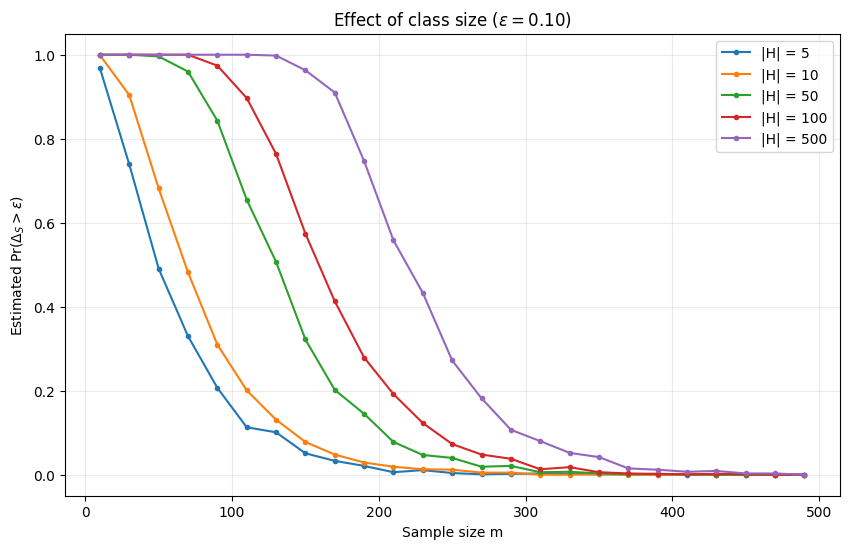

In [5]:
class_sizes_q4 = [5, 10, 50, 100, 500]
epsilon_q4 = 0.10
sample_sizes_q4 = np.arange(10, 501, 20)
n_sim_q4 = 1_000

all_true_risks_q4 = rng.uniform(0.1, 0.9, size=max(class_sizes_q4))
results_q4 = {}

plt.figure(figsize=(10, 6))

for K in class_sizes_q4:
    true_risks = all_true_risks_q4[:K]
    estimated_probs = []

    for m in sample_sizes_q4:
        errors = rng.binomial(
            n=m,
            p=true_risks,
            size=(n_sim_q4, K)
        )
        empirical_risks = errors / m
        max_deviation = np.max(np.abs(empirical_risks - true_risks), axis=1)
        estimated_probs.append(np.mean(max_deviation > epsilon_q4))

    results_q4[K] = np.array(estimated_probs)
    plt.plot(sample_sizes_q4, estimated_probs, marker="o", markersize=3,
             label=f"|H| = {K}")

plt.xlabel("Sample size m")
plt.ylabel(r"Estimated $\Pr(\Delta_S>\varepsilon)$")
plt.title(r"Effect of class size ($\varepsilon=0.10$)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Interprétation.** Avec un plus grand nombre d'hypothèses, il y a plus d'opportunités pour qu'au moins un risque empirique s'écarte de son risque réel. En général, une classe finie plus grande nécessite plus de données pour obtenir la même garantie uniforme. La borne théorique dépend de $\log |\mathcal{H}|$, de sorte que la taille d'échantillon suffisante croît de manière logarithmique avec la taille de la classe, et non de manière linéaire. Les courbes de Monte-Carlo peuvent encore se croiser localement en raison de la variabilité de l'échantillonnage ; la théorie donne une borne supérieure, pas un ordre exact de chaque courbe empirique.

### Question 5 — Complexité d'échantillonnage expérimentale

Pour une classe finie, le cours établit la condition suffisante suivante :

$$
2|\mathcal{H}|e^{-2m\varepsilon^2}\leq\delta,
$$

ce qui donne :

$$
m\geq
\frac{\log(2|\mathcal{H}|/\delta)}{2\varepsilon^2}.
$$

Je compare cette taille d'échantillon théorique suffisante avec la première taille d'échantillon testée pour laquelle l'estimation de Monte-Carlo de $\Pr(\Delta_S>\varepsilon)$ est inférieure ou égale à $\delta$. Le résultat expérimental dépend de la grille de valeurs testées et de l'incertitude de Monte-Carlo, ce n'est donc pas nécessairement le minimum exact.

Theoretical sufficient sample size: 381


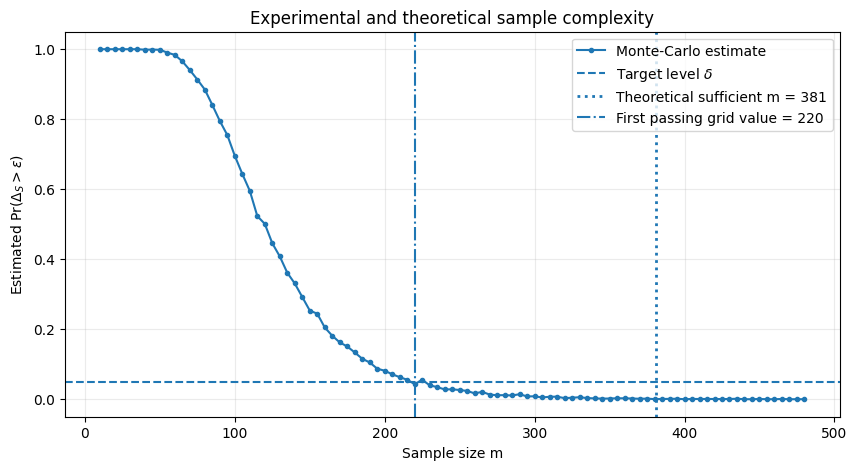

First passing tested grid value: 220
Reminder: the theoretical value is sufficient, not necessarily minimal.


In [6]:
K_q5 = 50
epsilon_q5 = 0.10
delta_q5 = 0.05
n_sim_q5 = 3_000

m_theory_q5 = int(np.ceil(np.log(2 * K_q5 / delta_q5) / (2 * epsilon_q5**2)))
print("Theoretical sufficient sample size:", m_theory_q5)

true_risks_q5 = rng.uniform(0.1, 0.9, size=K_q5)

# First use a grid to identify the approximate region, then check every integer nearby.
m_grid_q5 = np.arange(10, m_theory_q5 + 101, 5)
prob_grid_q5 = []

for m in m_grid_q5:
    errors = rng.binomial(n=m, p=true_risks_q5, size=(n_sim_q5, K_q5))
    empirical_risks = errors / m
    max_deviation = np.max(np.abs(empirical_risks - true_risks_q5), axis=1)
    prob_grid_q5.append(np.mean(max_deviation > epsilon_q5))

eligible = [m for m, prob in zip(m_grid_q5, prob_grid_q5) if prob <= delta_q5]
m_exp_grid_q5 = min(eligible) if eligible else None

plt.figure(figsize=(10, 5))
plt.plot(m_grid_q5, prob_grid_q5, marker="o", markersize=3,
         label="Monte-Carlo estimate")
plt.axhline(delta_q5, linestyle="--", label=r"Target level $\delta$")
plt.axvline(m_theory_q5, linestyle=":", linewidth=2,
            label=f"Theoretical sufficient m = {m_theory_q5}")
if m_exp_grid_q5 is not None:
    plt.axvline(m_exp_grid_q5, linestyle="-.",
                label=f"First passing grid value = {m_exp_grid_q5}")
plt.xlabel("Sample size m")
plt.ylabel(r"Estimated $\Pr(\Delta_S>\varepsilon)$")
plt.title("Experimental and theoretical sample complexity")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("First passing tested grid value:", m_exp_grid_q5)
print("Reminder: the theoretical value is sufficient, not necessarily minimal.")

**Interprétation.** La valeur théorique est conçue pour garantir une probabilité d'échec inférieure ou égale à $\delta$ sous les hypothèses de la borne. Ce n'est pas une équation donnant la probabilité d'échec exacte. Le seuil empirique peut être plus petit ou plus grand parce que la borne est conservatrice, parce que seule une grille de tailles d'échantillon est testée, et parce que l'estimation de Monte-Carlo comporte une incertitude d'échantillonnage.

## Partie II — Simulation du No-Free-Lunch

### Rappel du cours

Ici, le domaine d'entrée est fini, $\mathcal{X}=\{1,\ldots,N\}$, muni d'une distribution uniforme. Au début de chaque répétition, je génère une nouvelle fonction cible aléatoire en attribuant à chaque entrée une étiquette indépendante Bernoulli$(1/2)$.

L'algorithme d'apprentissage mémorise les étiquettes des entrées vues lors de l'entraînement et prédit $0$ pour les entrées jamais vues. Il s'agit délibérément d'un algorithme simple : il ne fait aucune hypothèse reliant l'étiquette d'une entrée à celle d'une autre.

### Question 6 — Entrées vues et non vues

Pour un point fixe $x$, chaque tirage l'évite avec une probabilité $1-1/N$. Les $m$ tirages étant indépendants :

$$
\Pr(x\text{ n'est pas vu})=\left(1-\frac1N\right)^m.
$$

Si $U$ est le nombre de points non observés, alors par linéarité de l'espérance :

$$
\mathbb{E}\left[\frac{U}{N}\right]
=\frac1N\sum_{x=1}^{N}\Pr(x\text{ n'est pas vu})
=\left(1-\frac1N\right)^m.
$$

Nous n'avons pas besoin que les événements "point non vu" soient indépendants pour ce calcul d'espérance.

N | m | simulated mean unseen fraction | theoretical value
 50 |  10 | 0.8172                       | 0.8171
 50 |  30 | 0.5462                       | 0.5455
100 |  30 | 0.7400                       | 0.7397
100 | 100 | 0.3666                       | 0.3660
200 | 100 | 0.6058                       | 0.6058


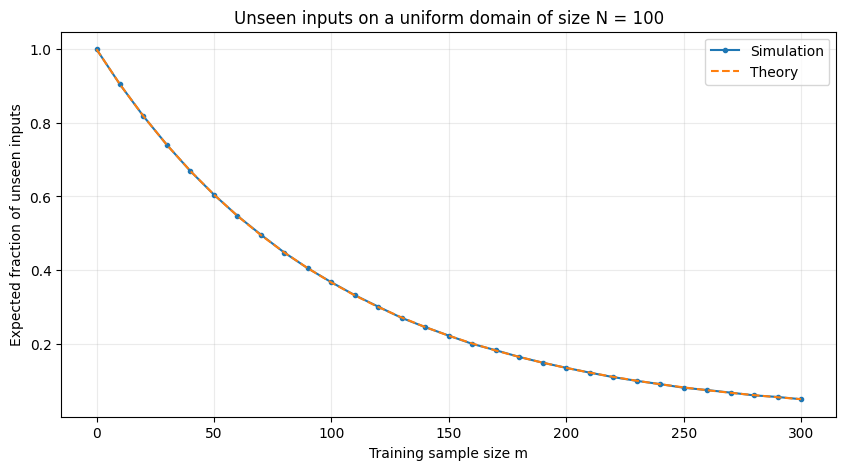

In [7]:
def simulate_unseen_fraction(N, m, n_repetitions, rng):
    fractions = np.empty(n_repetitions)

    for r in range(n_repetitions):
        # Sampling with replacement means an input may appear more than once.
        X_train = rng.integers(1, N + 1, size=m)
        n_seen = np.unique(X_train).size
        fractions[r] = (N - n_seen) / N

    return fractions

settings_q6 = [(50, 10), (50, 30), (100, 30), (100, 100), (200, 100)]
print("N | m | simulated mean unseen fraction | theoretical value")

q6_rows = []
for N, m in settings_q6:
    fractions = simulate_unseen_fraction(N, m, 5_000, rng)
    theoretical = (1 - 1 / N)**m
    simulated = fractions.mean()
    q6_rows.append((N, m, simulated, theoretical))
    print(f"{N:3d} | {m:3d} | {simulated:.4f}|                          {theoretical:.4f}")

# Plot one example as a function of m.
N_q6_plot = 100
m_values_q6_plot = np.arange(0, 301, 10)
simulated_means_q6 = []
theoretical_q6 = []

for m in m_values_q6_plot:
    fractions = simulate_unseen_fraction(N_q6_plot, m, 2_000, rng)
    simulated_means_q6.append(fractions.mean())
    theoretical_q6.append((1 - 1 / N_q6_plot)**m)

plt.figure(figsize=(10, 5))
plt.plot(m_values_q6_plot, simulated_means_q6, marker="o", markersize=3,
         label="Simulation")
plt.plot(m_values_q6_plot, theoretical_q6, linestyle="--",
         label="Theory")
plt.xlabel("Training sample size m")
plt.ylabel("Expected fraction of unseen inputs")
plt.title(f"Unseen inputs on a uniform domain of size N = {N_q6_plot}")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Interprétation.** La moyenne simulée doit être proche de la fraction théorique. À mesure que le nombre d'exemples d'entraînement augmente, les points ont plus de chances d'apparaître au moins une fois, de sorte que la fraction d'éléments non vus diminue. Les observations répétées expliquent pourquoi le nombre d'entrées distinctes observées peut être inférieur à $m$.

### Question 7 — Erreur sur les entrées non vues

L'algorithme par mémorisation prédit correctement l'étiquette observée pour chaque entrée qui apparaît dans l'échantillon. Pour une entrée non vue, il prédit $0$, tandis que l'étiquette cible reste une variable indépendante Bernoulli$(1/2)$. Sa probabilité d'erreur est donc de $1/2$.

En combinant cela avec la fraction attendue d'entrées non vues, on obtient :

$$
\mathbb{E}[L_D(A(S))]
=\frac12\left(1-\frac1N\right)^m.
$$

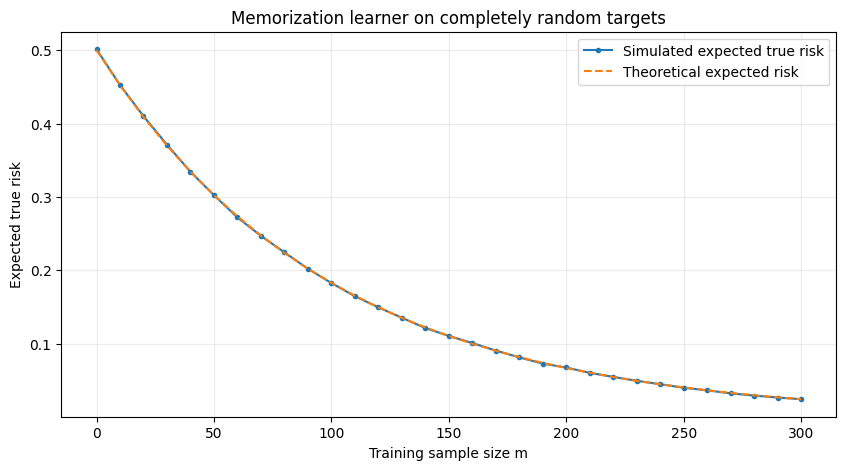

In [8]:
def simulate_random_target_risk(N, m, n_repetitions, rng, unseen_rule="zero"):
    risks = np.empty(n_repetitions)

    for r in range(n_repetitions):
        # A new random target function for each repetition.
        target = rng.integers(0, 2, size=N + 1)  # index 0 is unused
        X_train = rng.integers(1, N + 1, size=m)
        y_train = target[X_train]

        # Store the observed label for each input; -1 means "not observed".
        predictions = np.full(N + 1, -1, dtype=int)
        predictions[X_train] = y_train

        unseen = predictions[1:] == -1

        if unseen_rule == "zero":
            predictions[1:][unseen] = 0
        elif unseen_rule == "one":
            predictions[1:][unseen] = 1
        elif unseen_rule == "random":
            predictions[1:][unseen] = rng.integers(0, 2, size=unseen.sum())
        else:
            raise ValueError("unseen_rule must be 'zero', 'one', or 'random'")

        risks[r] = np.mean(predictions[1:] != target[1:])

    return risks

N_q7 = 100
m_values_q7 = np.arange(0, 301, 10)
n_sim_q7 = 3_000
simulated_risk_q7 = []
theoretical_risk_q7 = []

for m in m_values_q7:
    risks = simulate_random_target_risk(N_q7, m, n_sim_q7, rng, unseen_rule="zero")
    simulated_risk_q7.append(risks.mean())
    theoretical_risk_q7.append(0.5 * (1 - 1 / N_q7)**m)

plt.figure(figsize=(10, 5))
plt.plot(m_values_q7, simulated_risk_q7, marker="o", markersize=3,
         label="Simulated expected true risk")
plt.plot(m_values_q7, theoretical_risk_q7, linestyle="--",
         label="Theoretical expected risk")
plt.xlabel("Training sample size m")
plt.ylabel("Expected true risk")
plt.title("Memorization learner on completely random targets")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Interprétation.** Le risque diminue car l'algorithme a moins d'entrées non vues à deviner. Cependant, il ne suffit pas de dire que l'algorithme a observé de nombreux exemples : il doit avoir observé précisément l'entrée en question pour connaître son étiquette cible arbitraire. L'erreur restante provient des points non vus.

### Question 8 — Modification de la règle de prédiction sur les entrées non vues

Je compare trois règles pour les points non vus : toujours prédire $0$, toujours prédire $1$, ou tirer une prédiction aléatoire Bernoulli$(1/2)$. La même cible aléatoire et le même échantillon d'entraînement sont utilisés pour les trois règles au sein de chaque répétition, de sorte que la comparaison est appariée.

Domain size N=100, sample size m=40
Always 0      : mean risk = 0.3342, Monte-Carlo SE = 0.0004
Always 1      : mean risk = 0.3348, Monte-Carlo SE = 0.0004
Random label  : mean risk = 0.3338, Monte-Carlo SE = 0.0004


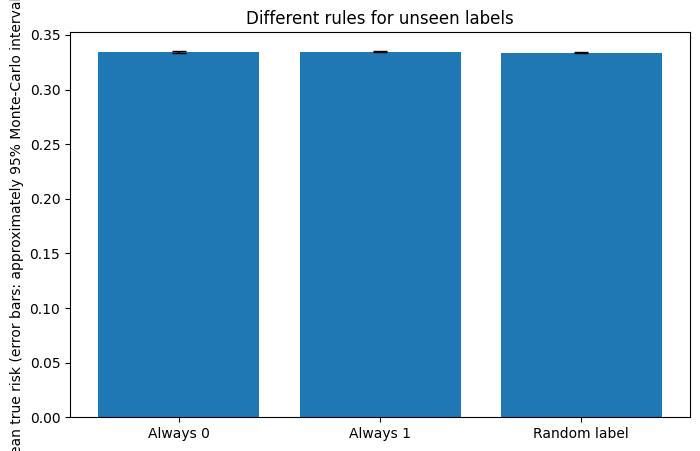

In [9]:
def compare_unseen_rules(N, m, n_repetitions, rng):
    risks = {"Always 0": [], "Always 1": [], "Random label": []}

    for _ in range(n_repetitions):
        target = rng.integers(0, 2, size=N + 1)
        X_train = rng.integers(1, N + 1, size=m)
        y_train = target[X_train]

        base_predictions = np.full(N + 1, -1, dtype=int)
        base_predictions[X_train] = y_train
        unseen = base_predictions[1:] == -1

        # Rule 1: predict zero on unseen points.
        pred_zero = base_predictions.copy()
        pred_zero[1:][unseen] = 0
        risks["Always 0"].append(np.mean(pred_zero[1:] != target[1:]))

        # Rule 2: predict one on unseen points.
        pred_one = base_predictions.copy()
        pred_one[1:][unseen] = 1
        risks["Always 1"].append(np.mean(pred_one[1:] != target[1:]))

        # Rule 3: choose a random binary label on unseen points.
        pred_random = base_predictions.copy()
        pred_random[1:][unseen] = rng.integers(0, 2, size=unseen.sum())
        risks["Random label"].append(np.mean(pred_random[1:] != target[1:]))

    return {name: np.asarray(values) for name, values in risks.items()}

N_q8 = 100
m_q8 = 40
risks_q8 = compare_unseen_rules(N_q8, m_q8, 10_000, rng)

print(f"Domain size N={N_q8}, sample size m={m_q8}")
for name, values in risks_q8.items():
    standard_error = values.std(ddof=1) / np.sqrt(len(values))
    print(f"{name:14s}: mean risk = {values.mean():.4f}, "
          f"Monte-Carlo SE = {standard_error:.4f}")

plt.figure(figsize=(8, 5))
names_q8 = list(risks_q8.keys())
means_q8 = [risks_q8[name].mean() for name in names_q8]
ses_q8 = [risks_q8[name].std(ddof=1) / np.sqrt(len(risks_q8[name]))
          for name in names_q8]
plt.bar(names_q8, means_q8, yerr=1.96 * np.array(ses_q8), capsize=5)
plt.ylabel("Mean true risk (error bars: approximately 95% Monte-Carlo intervals)")
plt.title("Different rules for unseen labels")
plt.show()

**Interprétation.** Sous l'hypothèse d'une cible aléatoire, l'étiquette non vue a autant de chances d'être $0$ ou $1$, indépendamment des données d'entraînement. Par conséquent, chacune des trois règles a une erreur attendue de $1/2$ sur les entrées non vues. Leurs moyennes observées n'ont pas besoin d'être exactement égales dans une simulation finie. Cela illustre le message du No-Free-Lunch : sans hypothèses sur la façon dont les étiquettes sont reliées entre les entrées, changer la règle de prédiction à l'aveugle ne crée pas d'information prédictive systématique.

## Partie III — Introduction de Connaissances a Priori

### Rappel du cours : le biais inductif

La partie précédente utilisait des fonctions cibles complètement arbitraires. Supposons maintenant que la cible appartienne à une famille spécifique de fonctions à seuil :

$$
f_\theta(x)=\mathbf{1}[x>\theta], \qquad
\theta\in\{1,\ldots,N-1\}.
$$

L'algorithme d'apprentissage est restreint à cette même famille :

$$
\mathcal{H}=\{h_t(x)=\mathbf{1}[x>t]:t\in\{1,\ldots,N-1\}\}.
$$

Cette restriction constitue un **biais inductif** : elle exprime une connaissance préalable sur la forme de la cible. Si l'hypothèse est correcte, les étiquettes aux points observés contraignent le seuil possible et fournissent donc des informations sur les points non vus.

### Question 9 — Apprentissage avec un biais inductif adapté

J'implémente la minimisation du risque empirique (ERM) en évaluant chaque seuil de la classe d'hypothèses et en sélectionnant celui qui présente le plus petit nombre d'erreurs d'entraînement. Comme la cible est elle-même un seuil, au moins une hypothèse présente une erreur empirique nulle : le vrai seuil appartient à la classe.

Si plusieurs seuils obtiennent une erreur empirique nulle, le code ci-dessous choisit le plus petit. Cette règle de départage est simple et déterministe.

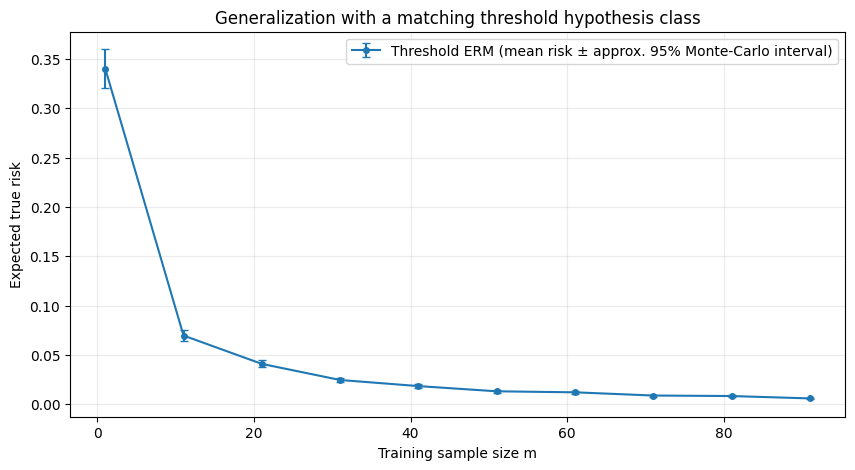

Maximum empirical error count observed by ERM: 0


In [10]:
def threshold_labels(x, threshold):
    return (np.asarray(x) > threshold).astype(int)

def erm_threshold(X_train, y_train, N):
    candidate_thresholds = np.arange(1, N)  # thresholds 1, ..., N-1

    # Evaluate every candidate threshold in one vectorized operation.
    # Rows correspond to training examples and columns to candidate thresholds.
    predictions = X_train[:, None] > candidate_thresholds[None, :]
    empirical_errors = np.sum(predictions != y_train[:, None], axis=0)

    # np.argmin returns the first minimum, so ties select the smallest threshold.
    best_index = int(np.argmin(empirical_errors))
    best_threshold = candidate_thresholds[best_index]
    best_error_count = empirical_errors[best_index]

    return int(best_threshold), int(best_error_count)

def simulate_threshold_erm_risk(N, m, n_repetitions, rng):
    domain = np.arange(1, N + 1)
    risks = np.empty(n_repetitions)
    empirical_errors = np.empty(n_repetitions, dtype=int)

    for r in range(n_repetitions):
        theta = rng.integers(1, N)  # integer in {1, ..., N-1}
        X_train = rng.integers(1, N + 1, size=m)
        y_train = threshold_labels(X_train, theta)

        learned_t, min_error_count = erm_threshold(X_train, y_train, N)
        learned_predictions = threshold_labels(domain, learned_t)
        true_labels = threshold_labels(domain, theta)

        # Uniform distribution on the finite domain: true risk is the fraction
        # of domain points where the learned and true threshold disagree.
        risks[r] = np.mean(learned_predictions != true_labels)
        empirical_errors[r] = min_error_count

    return risks, empirical_errors

N_q9 = 100
m_values_q9 = np.arange(1, 101, 10)
n_sim_q9 = 600
mean_risk_q9 = []
se_risk_q9 = []
all_empirical_errors_q9 = []

for m in m_values_q9:
    risks, errors = simulate_threshold_erm_risk(N_q9, m, n_sim_q9, rng)
    mean_risk_q9.append(risks.mean())
    se_risk_q9.append(risks.std(ddof=1) / np.sqrt(n_sim_q9))
    all_empirical_errors_q9.extend(errors.tolist())

plt.figure(figsize=(10, 5))
plt.errorbar(m_values_q9, mean_risk_q9, yerr=1.96 * np.array(se_risk_q9),
             marker="o", markersize=4, capsize=3,
             label="Threshold ERM (mean risk ± approx. 95% Monte-Carlo interval)")
plt.xlabel("Training sample size m")
plt.ylabel("Expected true risk")
plt.title("Generalization with a matching threshold hypothesis class")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("Maximum empirical error count observed by ERM:", max(all_empirical_errors_q9))

**Interprétation.** L'ERM doit obtenir une erreur d'entraînement nulle car le vrai seuil appartient à la classe d'hypothèses. Son risque réel peut néanmoins être positif : plusieurs seuils peuvent s'accorder sur les exemples observés mais différer sur les points non observés du domaine. À mesure que $m$ augmente, les observations contraignent le seuil plus étroitement, et le risque réel moyen doit diminuer.

C'est un exemple du rôle des connaissances a priori. L'algorithme ne devine pas une étiquette indépendante à chaque point non vu ; il utilise l'hypothèse de seuil pour relier les étiquettes à travers le domaine.

### Question 10 — Cibles aléatoires vs cibles structurées

Je compare le risque réel attendu de l'algorithme de mémorisation sur des cibles aléatoires avec le risque réel attendu de l'ERM par seuil sur des cibles à seuil. Il s'agit de problèmes d'apprentissage différents qui reposent sur des hypothèses différentes. Dans le premier cas, les étiquettes non vues sont des bits aléatoires indépendants ; dans le second, toutes les étiquettes sont déterminées par un unique paramètre de seuil.

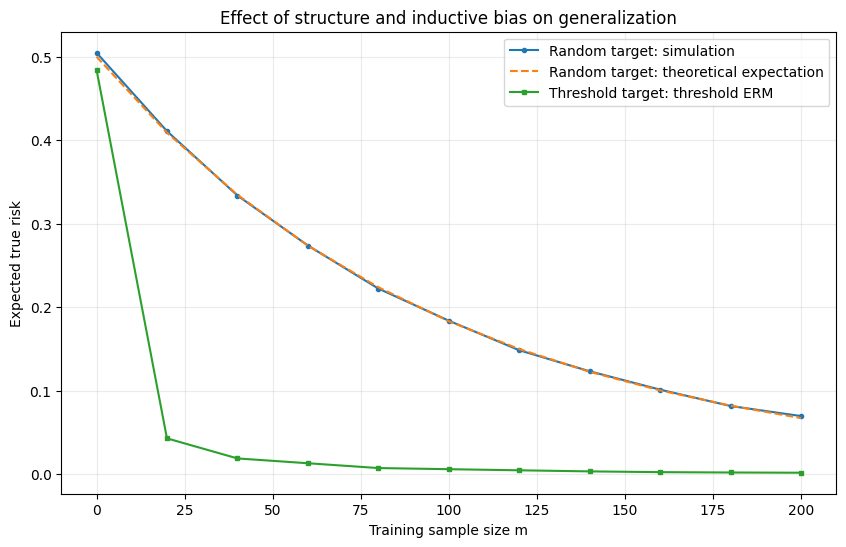

In [11]:
N_q10 = 100
m_values_q10 = np.arange(0, 201, 20)
n_sim_q10 = 800

random_target_means_q10 = []
threshold_means_q10 = []
random_target_theory_q10 = []

for m in m_values_q10:
    # Part II: memorization on a completely random target.
    random_risks = simulate_random_target_risk(
        N_q10, m, n_sim_q10, rng, unseen_rule="zero"
    )
    random_target_means_q10.append(random_risks.mean())
    random_target_theory_q10.append(0.5 * (1 - 1 / N_q10)**m)

    # Part III: ERM on a threshold target.
    threshold_risks, _ = simulate_threshold_erm_risk(
        N_q10, m, n_sim_q10, rng
    )
    threshold_means_q10.append(threshold_risks.mean())

plt.figure(figsize=(10, 6))
plt.plot(m_values_q10, random_target_means_q10, marker="o", markersize=3,
         label="Random target: simulation")
plt.plot(m_values_q10, random_target_theory_q10, linestyle="--",
         label="Random target: theoretical expectation")
plt.plot(m_values_q10, threshold_means_q10, marker="s", markersize=3,
         label="Threshold target: threshold ERM")
plt.xlabel("Training sample size m")
plt.ylabel("Expected true risk")
plt.title("Effect of structure and inductive bias on generalization")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Interprétation.** Pour le problème de la cible aléatoire, l'algorithme par mémorisation ne peut être sûr que des étiquettes qu'il a observées. Pour les cibles à seuil, une seule étiquette observée contraint le seuil, et l'hypothèse de seuil lie les prédictions entre les différentes entrées. C'est pourquoi le problème structuré permet de généraliser plus efficacement.

Cette conclusion dépend de la pertinence de l'hypothèse. Si la cible réelle n'était pas un seuil, restreindre l'apprentissage aux seuils pourrait introduire une erreur d'approximation. Cela renvoie au compromis biais-complexité de la Session 4 : une classe plus restrictive peut être plus facile à estimer à partir de données finies, mais elle peut ne pas être capable de représenter toutes les cibles possibles.

### Question 11 — Analyse finale

Les expériences illustrent les idées principales des deux sessions de cours.

- **Concentration et convergence uniforme.** Pour une hypothèse fixée, le risque empirique est une moyenne de pertes bornées. Sa variance diminue avec $m$, et l'inégalité de Hoeffding borne la probabilité d'un écart important. La convergence uniforme exige que l'écart soit faible pour toutes les hypothèses à la fois. La borne de l'union introduit le facteur $|\mathcal{H}|$, ce qui conduit à une borne de taille d'échantillon suffisante qui dépend de $\log |\mathcal{H}|$.

- **Pourquoi les bornes peuvent être conservatrices.** L'inégalité de Hoeffding et la borne de l'union fournissent des garanties, et non des probabilités d'échec exactes. Elles peuvent surestimer la probabilité d'échec observée. Une estimation finie par Monte-Carlo présente également une incertitude d'échantillonnage.

- **No-Free-Lunch.** Pour une cible complètement aléatoire, les étiquettes des entrées non observées sont indépendantes des étiquettes observées. L'algorithme ne peut pas déduire des étiquettes non vues arbitraires à partir du seul échantillon d'apprentissage. Différentes règles de prédiction ont la même erreur attendue sur les points non vus sous le modèle de cible Bernoulli$(1/2)$.

- **Biais inductif et généralisation.** Lorsque la cible est un seuil et que l'algorithme sait qu'il doit chercher parmi les fonctions à seuil, les étiquettes ne sont pas arbitraires : elles sont liées par une structure simple. L'ERM peut utiliser cette hypothèse pour contraindre les prédictions sur les entrées non observées.

- **Compromis biais-complexité.** Restreindre la classe d'hypothèses peut réduire la difficulté d'estimation, mais cela peut aussi créer une erreur d'approximation si la classe ne peut pas représenter la cible. Une classe d'hypothèses utile doit être suffisamment expressive pour la tâche sans être inutilement complexe par rapport à la quantité de données disponibles.

Globalement, les simulations confirment le message du cours : une bonne généralisation ne provient pas de la seule minimisation du risque empirique. Elle dépend également de la quantité de données disponibles et de l'utilisation d'hypothèses sur la cible qui sont adaptées au problème d'apprentissage.

## Note sur l'utilisation de l'intelligence artificielle

Note : Dans le cadre de ce devoir, l'intelligence artificielle a été utilisée comme outil d'assistance pour la rédaction, la structuration et l'implémentation du code de programmation (simulation, calculs de Monte-Carlo et visualisations graphiques).
